Clasificación de defectos en álabes de motores de avión

Objetivo: clasificar fotos de álabes en 5 clases (good, ablation, breakdown, fracture, groove) usando transfer learning con modelos preentrenados de timm, y compararlos contra CLIP sin entrenar como línea base.

In [1]:
!pip install -q timm gdown

import os, random, hashlib, shutil, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import timm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


## 1. Datos

### 1.1 Origen del dataset
- **Nombre:** AeBAD (*Aero-engine Blade Anomaly Detection*), subconjunto **AeBAD-S** (un álabe por imagen).
- **Autores:** Zhang, Zhao, Zhang, Sun y Chen (Xi'an Jiaotong University).
- **Paper:** *Industrial Anomaly Detection with Domain Shift: A Real-world Dataset and Masked Multi-scale Reconstruction*, arXiv:2304.02216 (2023).
- **Cómo se obtuvo:** fotos reales de álabes de motores aeronáuticos con distintos defectos, tomadas con variaciones de iluminación, fondo y punto de vista.

### 1.2 Descarga

In [2]:
!gdown 14wkZAFFeudlg0NMFLsiGwS0E593b-lNo -O AeBAD.zip
!file AeBAD.zip
!unzip -q -o AeBAD.zip -d /content/data

Downloading...
From (original): https://drive.google.com/uc?id=14wkZAFFeudlg0NMFLsiGwS0E593b-lNo
From (redirected): https://drive.google.com/uc?id=14wkZAFFeudlg0NMFLsiGwS0E593b-lNo&confirm=t&uuid=c95ac9a5-efd1-40a1-84cb-29e9b7902ed0
To: /content/AeBAD.zip
100% 1.62G/1.62G [00:20<00:00, 80.7MB/s]
AeBAD.zip: Zip archive data, at least v2.0 to extract, compression method=store


### 1.3 Reunir imágenes por clase (excluyendo máscaras y videos)

In [11]:
from PIL import Image

raiz = "/content/data"
CLASES = ["good", "ablation", "breakdown", "fracture", "groove"]
rutas = []
etiquetas = []
descartados = 0

for dirpath, dirs, files in os.walk(raiz):
    partes = dirpath.split(os.sep)
    if "ground_truth" in partes or "AeBAD_V" in partes or "__MACOSX" in partes:
        continue
    clase = None
    for p in partes:
        if p in CLASES:
            clase = p
    if clase is None:
        continue
    for f in files:
        if f.startswith("."):
            continue  # archivos ocultos de macOS (._xxx.png), no son imágenes
        if not f.lower().endswith((".png", ".jpg", ".jpeg")):
            continue
        ruta = os.path.join(dirpath, f)
        try:
            with Image.open(ruta) as im:
                im.verify()  # comprueba que sea una imagen real
        except Exception:
            descartados += 1
            continue
        rutas.append(ruta)
        etiquetas.append(clase)

print("Archivos no válidos descartados:", descartados)
print(len(rutas), Counter(etiquetas))

Archivos no válidos descartados: 0
2160 Counter({'good': 1011, 'fracture': 389, 'breakdown': 329, 'groove': 262, 'ablation': 169})


### 1.4 Eliminar duplicados (evita *data leakage* entre train y test)

In [12]:
vistos = {}
rutas_limpias = []
etiquetas_limpias = []
duplicados = 0
conflictos = 0

for i in range(len(rutas)):
    with open(rutas[i], "rb") as fh:
        h = hashlib.md5(fh.read()).hexdigest()
    if h in vistos:
        duplicados += 1
        if vistos[h] != etiquetas[i]:
            conflictos += 1
        continue
    vistos[h] = etiquetas[i]
    rutas_limpias.append(rutas[i])
    etiquetas_limpias.append(etiquetas[i])

print("Duplicados eliminados:", duplicados)
print("Duplicados con etiqueta distinta:", conflictos)
rutas = rutas_limpias
etiquetas = etiquetas_limpias
print(len(rutas), Counter(etiquetas))

Duplicados eliminados: 1
Duplicados con etiqueta distinta: 0
2159 Counter({'good': 1010, 'fracture': 389, 'breakdown': 329, 'groove': 262, 'ablation': 169})


### 1.5 Imágenes por clase y desbalance

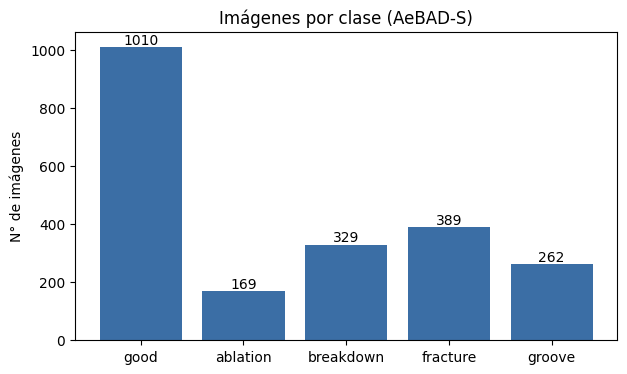

good        1010  (46.8%)
ablation     169  (7.8%)
breakdown    329  (15.2%)
fracture     389  (18.0%)
groove       262  (12.1%)
Razón clase mayor / menor: 6.0


In [13]:
conteo = Counter(etiquetas)
nombres = []
valores = []
for c in CLASES:
    nombres.append(c)
    valores.append(conteo[c])

plt.figure(figsize=(7, 4))
plt.bar(nombres, valores, color="#3b6ea5")
for i in range(len(valores)):
    plt.text(i, valores[i] + 10, str(valores[i]), ha="center")
plt.title("Imágenes por clase (AeBAD-S)")
plt.ylabel("N° de imágenes")
plt.show()

total = sum(valores)
for i in range(len(nombres)):
    print(f"{nombres[i]:10s} {valores[i]:5d}  ({100*valores[i]/total:.1f}%)")
print("Razón clase mayor / menor:", round(max(valores) / min(valores), 1))

**Comentario:** el dataset está **desbalanceado**: `good` es cerca de la mitad de las imágenes y `ablation` la clase más pequeña. Por eso usamos **pesos por clase** en la función de pérdida y reportamos **accuracy balanceada** y **F1 macro**, además de la accuracy.

### 1.6 Split 70 / 15 / 15 estratificado

In [15]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    rutas, etiquetas, test_size=0.30, stratify=etiquetas, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

destino = "/content/aebad_cls"
if os.path.exists(destino):
    shutil.rmtree(destino)

splits = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
for nombre in splits:
    X, y = splits[nombre]
    for i in range(len(X)):
        carpeta = os.path.join(destino, nombre, y[i])
        os.makedirs(carpeta, exist_ok=True)
        ext = os.path.splitext(X[i])[1]
        shutil.copy(X[i], os.path.join(carpeta, f"{y[i]}_{i:05d}{ext}"))
    print(nombre, len(X), Counter(y))

train 1511 Counter({'good': 707, 'fracture': 272, 'breakdown': 230, 'groove': 184, 'ablation': 118})
val 324 Counter({'good': 151, 'fracture': 58, 'breakdown': 50, 'groove': 39, 'ablation': 26})
test 324 Counter({'good': 152, 'fracture': 59, 'breakdown': 49, 'groove': 39, 'ablation': 25})


**Cómo se hizo el split:** 70% entrenamiento, 15% validación y 15% prueba, **estratificado** por clase (cada conjunto mantiene las proporciones) y con semilla fija (`random_state=42`) para que sea reproducible. Validación se usa para elegir la mejor época; prueba se usa **una sola vez** al final.

**Limitaciones de los datos:**
- Proviene de **una sola fuente** (un laboratorio, un tipo de motor), por lo que puede no generalizar a otros motores o cámaras.
- Hay **desbalance** entre clases (`ablation` tiene pocas imágenes).
- Varias fotos son del **mismo álabe** con distinta iluminación o ángulo; aunque eliminamos duplicados exactos, fotos casi iguales pueden quedar en train y test e inflar algo las métricas.
- Cada imagen tiene **una sola etiqueta**, aunque en la realidad un álabe podría tener más de un defecto.

### 1.7 Ejemplos

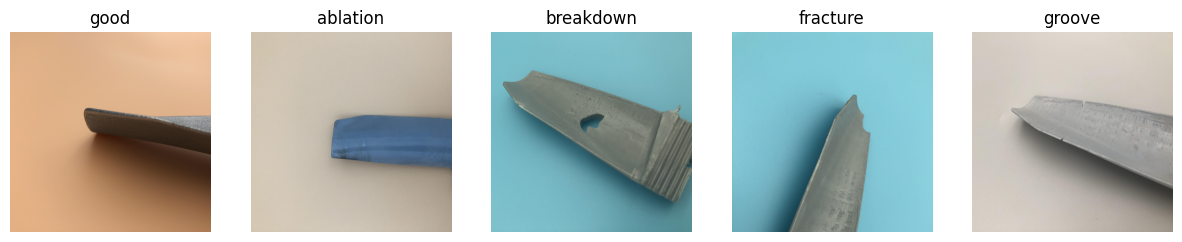

In [17]:
plt.figure(figsize=(15, 3.5))
for i in range(len(CLASES)):
    c = CLASES[i]
    carpeta = os.path.join(destino, "train", c)
    archivo = sorted(os.listdir(carpeta))[0]
    img = Image.open(os.path.join(carpeta, archivo)).convert("RGB")
    plt.subplot(1, len(CLASES), i + 1)
    plt.imshow(img)
    plt.title(c)
    plt.axis("off")
plt.show()

## 2. DataLoaders

In [18]:
IMG = 224
MEDIA = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

tf_train = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, STD),
])
tf_eval = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, STD),
])

ds_train = datasets.ImageFolder(os.path.join(destino, "train"), tf_train)
ds_val = datasets.ImageFolder(os.path.join(destino, "val"), tf_eval)
ds_test = datasets.ImageFolder(os.path.join(destino, "test"), tf_eval)
NOMBRES = ds_train.classes
print("Clases (orden del modelo):", NOMBRES)

dl_train = DataLoader(ds_train, batch_size=32, shuffle=True, num_workers=2)
dl_val = DataLoader(ds_val, batch_size=64, shuffle=False, num_workers=2)
dl_test = DataLoader(ds_test, batch_size=64, shuffle=False, num_workers=2)

# Pesos por clase: inversamente proporcionales a la frecuencia
conteo_train = Counter(ds_train.targets)
pesos = []
for i in range(len(NOMBRES)):
    pesos.append(len(ds_train.targets) / (len(NOMBRES) * conteo_train[i]))
pesos = torch.tensor(pesos, dtype=torch.float).to(device)
for i in range(len(NOMBRES)):
    print(f"{NOMBRES[i]:10s} peso = {pesos[i].item():.2f}")

Clases (orden del modelo): ['ablation', 'breakdown', 'fracture', 'good', 'groove']
ablation   peso = 2.56
breakdown  peso = 1.31
fracture   peso = 1.11
good       peso = 0.43
groove     peso = 1.64


## 3. Funciones de entrenamiento y evaluación

In [20]:
def predecir(modelo, loader):
    modelo.eval()
    y_true = []
    y_pred = []
    y_prob = []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            probs = torch.softmax(modelo(x), dim=1).cpu()
            y_prob.append(probs)
            y_pred.extend(probs.argmax(1).tolist())
            y_true.extend(y.tolist())
    return np.array(y_true), np.array(y_pred), torch.cat(y_prob).numpy()


def entrenar(nombre_timm, epocas_cabeza=3, epocas_fino=12, lr_cabeza=1e-3, lr_fino=1e-4):
    modelo = timm.create_model(nombre_timm, pretrained=True, num_classes=len(NOMBRES)).to(device)
    criterio = nn.CrossEntropyLoss(weight=pesos)
    historial = {"loss": [], "val_f1": []}
    mejor_f1 = -1
    ruta_mejor = f"/content/mejor_{nombre_timm}.pt"

    # Fase 1: solo la cabeza (base congelada)
    for p in modelo.parameters():
        p.requires_grad = False
    for p in modelo.get_classifier().parameters():
        p.requires_grad = True
    fases = [("cabeza", epocas_cabeza, lr_cabeza), ("fine-tuning", epocas_fino, lr_fino)]

    for fase, n_ep, lr in fases:
        if fase == "fine-tuning":
            for p in modelo.parameters():
                p.requires_grad = True
        opt = torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad],
                                lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_ep)
        for ep in range(n_ep):
            modelo.train()
            perdida_total = 0
            for x, y in dl_train:
                x, y = x.to(device), y.to(device)
                opt.zero_grad()
                loss = criterio(modelo(x), y)
                loss.backward()
                opt.step()
                perdida_total += loss.item() * x.size(0)
            sched.step()
            yt, yp, _ = predecir(modelo, dl_val)
            f1 = f1_score(yt, yp, average="macro")
            historial["loss"].append(perdida_total / len(ds_train))
            historial["val_f1"].append(f1)
            marca = ""
            if f1 > mejor_f1:
                mejor_f1 = f1
                torch.save(modelo.state_dict(), ruta_mejor)
                marca = "  <- mejor"
            print(f"[{nombre_timm}] {fase} ep {ep+1}/{n_ep}  loss={historial['loss'][-1]:.4f}  val_F1={f1:.4f}{marca}")

    modelo.load_state_dict(torch.load(ruta_mejor))
    return modelo, historial


def metricas(nombre, y_true, y_pred):
    return {
        "modelo": nombre,
        "accuracy": accuracy_score(y_true, y_pred),
        "accuracy_balanceada": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }


def matriz(nombre, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=NOMBRES)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Matriz de confusión – {nombre} (test)")
    plt.xticks(rotation=30)
    plt.show()
    return cm

## 4. Entrenamiento

Entrenamos dos modelos de **timm** con el mismo pipeline:
- **EfficientNet-B0**: liviano (~5M parámetros), ideal para publicar en la app.
- **ResNet-50**: más grande (~25M parámetros), un clásico como punto de comparación.

Cada uno se entrena en dos fases: primero solo la cabeza (base congelada) y luego *fine-tuning* de toda la red. Se guarda la época con mejor **F1 macro en validación**.

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[efficientnet_b0] cabeza ep 1/3  loss=3.0918  val_F1=0.2493  <- mejor
[efficientnet_b0] cabeza ep 2/3  loss=2.7395  val_F1=0.2701  <- mejor
[efficientnet_b0] cabeza ep 3/3  loss=2.5628  val_F1=0.2946  <- mejor
[efficientnet_b0] fine-tuning ep 1/12  loss=1.6480  val_F1=0.6269  <- mejor
[efficientnet_b0] fine-tuning ep 2/12  loss=0.8608  val_F1=0.6690  <- mejor
[efficientnet_b0] fine-tuning ep 3/12  loss=0.6069  val_F1=0.7937  <- mejor
[efficientnet_b0] fine-tuning ep 4/12  loss=0.4253  val_F1=0.7998  <- mejor
[efficientnet_b0] fine-tuning ep 5/12  loss=0.3338  val_F1=0.7768
[efficientnet_b0] fine-tuning ep 6/12  loss=0.3138  val_F1=0.8379  <- mejor
[efficientnet_b0] fine-tuning ep 7/12  loss=0.2312  val_F1=0.8787  <- mejor
[efficientnet_b0] fine-tuning ep 8/12  loss=0.2350  val_F1=0.8720
[efficientnet_b0] fine-tuning ep 9/12  loss=0.2045  val_F1=0.8768
[efficientnet_b0] fine-tuning ep 10/12  loss=0.1691  val_F1=0.8584
[efficientnet_b0] fine-tuning ep 11/12  loss=0.1748  val_F1=0.8696
[e

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

[resnet50] cabeza ep 1/3  loss=1.5836  val_F1=0.4352  <- mejor
[resnet50] cabeza ep 2/3  loss=1.5108  val_F1=0.4290
[resnet50] cabeza ep 3/3  loss=1.4689  val_F1=0.3779
[resnet50] fine-tuning ep 1/12  loss=1.3818  val_F1=0.4736  <- mejor
[resnet50] fine-tuning ep 2/12  loss=1.1471  val_F1=0.6036  <- mejor
[resnet50] fine-tuning ep 3/12  loss=0.8637  val_F1=0.7217  <- mejor
[resnet50] fine-tuning ep 4/12  loss=0.6655  val_F1=0.7628  <- mejor
[resnet50] fine-tuning ep 5/12  loss=0.5649  val_F1=0.7950  <- mejor
[resnet50] fine-tuning ep 6/12  loss=0.4742  val_F1=0.8145  <- mejor
[resnet50] fine-tuning ep 7/12  loss=0.4279  val_F1=0.8393  <- mejor
[resnet50] fine-tuning ep 8/12  loss=0.3538  val_F1=0.8521  <- mejor
[resnet50] fine-tuning ep 9/12  loss=0.3510  val_F1=0.8426
[resnet50] fine-tuning ep 10/12  loss=0.3255  val_F1=0.8591  <- mejor
[resnet50] fine-tuning ep 11/12  loss=0.3296  val_F1=0.8504
[resnet50] fine-tuning ep 12/12  loss=0.3167  val_F1=0.8624  <- mejor


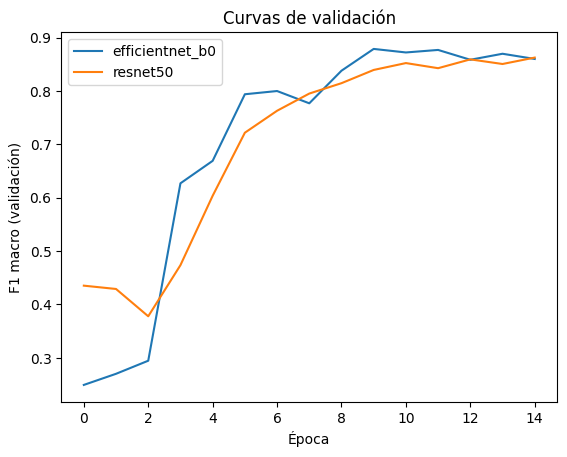

In [21]:
resultados = []
modelos = {}
tiempos = {}

for nombre in ["efficientnet_b0", "resnet50"]:
    t0 = time.time()
    modelo, hist = entrenar(nombre)
    tiempos[nombre] = time.time() - t0
    modelos[nombre] = modelo
    plt.plot(hist["val_f1"], label=nombre)

plt.xlabel("Época"); plt.ylabel("F1 macro (validación)")
plt.title("Curvas de validación"); plt.legend(); plt.show()

## 5. Evaluación en el conjunto de prueba

===== efficientnet_b0 =====
              precision    recall  f1-score   support

    ablation      0.808     0.840     0.824        25
   breakdown      0.960     0.980     0.970        49
    fracture      0.873     0.814     0.842        59
        good      0.926     0.908     0.917       152
      groove      0.636     0.718     0.675        39

    accuracy                          0.873       324
   macro avg      0.841     0.852     0.845       324
weighted avg      0.878     0.873     0.875       324



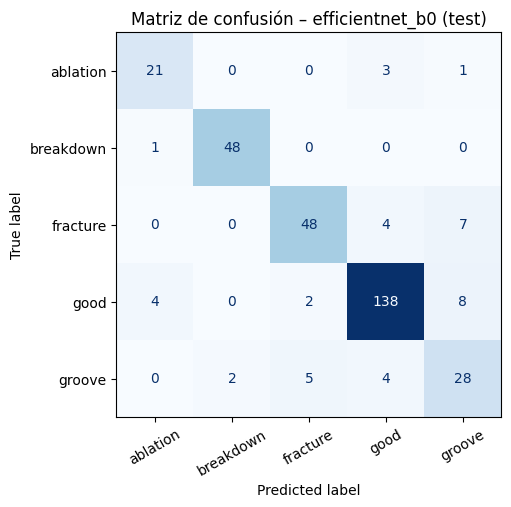

===== resnet50 =====
              precision    recall  f1-score   support

    ablation      0.875     0.840     0.857        25
   breakdown      0.980     1.000     0.990        49
    fracture      0.980     0.814     0.889        59
        good      0.903     0.914     0.908       152
      groove      0.723     0.872     0.791        39

    accuracy                          0.898       324
   macro avg      0.892     0.888     0.887       324
weighted avg      0.905     0.898     0.899       324



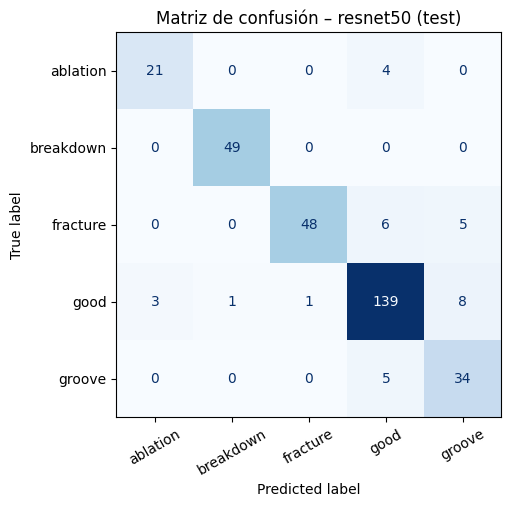

In [22]:
preds_test = {}
for nombre in modelos:
    yt, yp, _ = predecir(modelos[nombre], dl_test)
    preds_test[nombre] = (yt, yp)
    resultados.append(metricas(nombre, yt, yp))
    print(f"===== {nombre} =====")
    print(classification_report(yt, yp, target_names=NOMBRES, digits=3))
    matriz(nombre, yt, yp)

## 6. Línea base: CLIP sin entrenar (*zero-shot*)

CLIP compara la imagen con descripciones de texto de cada clase, sin ver ningún ejemplo de entrenamiento. Sirve para mostrar cuánto aporta el *transfer learning*.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

              precision    recall  f1-score   support

    ablation      0.333     0.080     0.129        25
   breakdown      0.471     0.673     0.555        49
    fracture      0.281     0.153     0.198        59
        good      0.605     0.513     0.555       152
      groove      0.103     0.231     0.143        39

    accuracy                          0.404       324
   macro avg      0.359     0.330     0.316       324
weighted avg      0.444     0.404     0.407       324



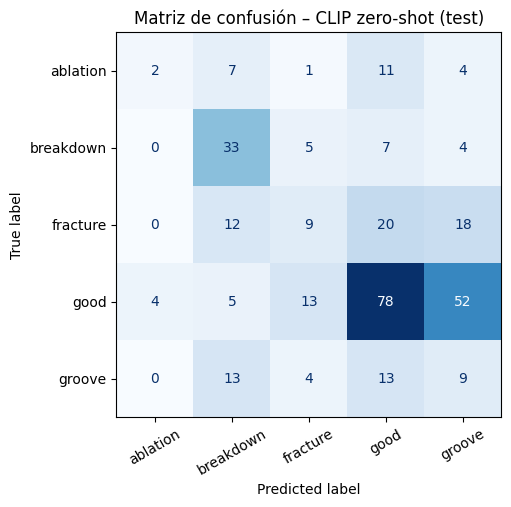

array([[ 2,  7,  1, 11,  4],
       [ 0, 33,  5,  7,  4],
       [ 0, 12,  9, 20, 18],
       [ 4,  5, 13, 78, 52],
       [ 0, 13,  4, 13,  9]])

In [23]:
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

DESCRIPCIONES = {
    "good": "a photo of an undamaged, clean aircraft engine turbine blade",
    "ablation": "a photo of an aircraft engine blade with burned, ablated surface",
    "breakdown": "a photo of an aircraft engine blade with a broken, missing piece",
    "fracture": "a photo of an aircraft engine blade with a crack fracture",
    "groove": "a photo of an aircraft engine blade with a scratched groove on the surface",
}
textos = []
for c in NOMBRES:
    textos.append(DESCRIPCIONES[c])

y_true_clip = []
y_pred_clip = []
muestras = ds_test.samples
for i in range(0, len(muestras), 32):
    lote = muestras[i:i + 32]
    imgs = []
    for ruta, etiqueta in lote:
        imgs.append(Image.open(ruta).convert("RGB"))
        y_true_clip.append(etiqueta)
    entrada = proc(text=textos, images=imgs, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        logits = clip(**entrada).logits_per_image
    y_pred_clip.extend(logits.argmax(1).cpu().tolist())

y_true_clip = np.array(y_true_clip)
y_pred_clip = np.array(y_pred_clip)
preds_test["clip_zero_shot"] = (y_true_clip, y_pred_clip)
resultados.append(metricas("clip_zero_shot", y_true_clip, y_pred_clip))
print(classification_report(y_true_clip, y_pred_clip, target_names=NOMBRES, digits=3, zero_division=0))
matriz("CLIP zero-shot", y_true_clip, y_pred_clip)

## 7. Comparación de modelos

In [24]:
import pandas as pd

n_params = {}
for nombre in modelos:
    n_params[nombre] = sum(p.numel() for p in modelos[nombre].parameters()) / 1e6

tabla = pd.DataFrame(resultados).set_index("modelo")
tabla["parametros_M"] = [n_params.get(m, np.nan) for m in tabla.index]
tabla["tiempo_entreno_min"] = [tiempos.get(m, 0) / 60 for m in tabla.index]
tabla.round(3)

,accuracy,accuracy_balanceada,f1_macro,parametros_M,tiempo_entreno_min
modelo,,,,,
efficientnet_b0,0.873,0.852,0.845,4.014,35.860
resnet50,0.898,0.888,0.887,23.518,40.533
clip_zero_shot,0.404,0.330,0.316,NaN,0.000


### Justificación de la elección del modelo

**Métrica principal:** se usa el **F1 macro** y la **accuracy balanceada**, no solo la accuracy, porque el dataset está desbalanceado.

**1. El transfer learning es necesario.** CLIP sin entrenar obtuvo un F1 macro de 0.316, apenas sobre el azar (0.20 para 5 clases). Un modelo general no distingue defectos tan específicos como fracturas o ranuras en álabes. Ajustar un modelo preentrenado a nuestros datos mejora el F1 en más de 50 puntos.

**2. ResNet-50 es el mejor modelo.** Supera a EfficientNet-B0 en las tres métricas, con unos 4 puntos más de F1 macro (0.887 vs 0.845) y de accuracy balanceada (0.888 vs 0.852).

**Modelo elegido: ResNet-50.**

## 8. El error más costoso

En inspección aeronáutica, el peor error es un **falso negativo**: el modelo dice `good` cuando el álabe tiene un defecto. Ese álabe volvería al motor y una fractura o ruptura podría crecer en operación, con riesgo de falla en vuelo. En cambio, un **falso positivo** (`good` marcado como defectuoso) solo cuesta una inspección manual extra.

También importa confundir defectos entre sí (por ejemplo `fracture` como `groove`), porque cambia la acción de mantenimiento, pero es menos grave que dejar pasar el defecto.

In [25]:
idx_good = NOMBRES.index("good")

for nombre in preds_test:
    yt, yp = preds_test[nombre]
    es_defecto = yt != idx_good
    defectos_como_good = int(np.sum(es_defecto & (yp == idx_good)))
    total_defectos = int(np.sum(es_defecto))
    good_como_defecto = int(np.sum((yt == idx_good) & (yp != idx_good)))
    recall_defecto = 1 - defectos_como_good / total_defectos
    print(f"{nombre:16s} defectos que pasaron como 'good': {defectos_como_good}/{total_defectos}"
          f"  -> recall de defecto = {recall_defecto:.3f}   |  falsas alarmas: {good_como_defecto}")

efficientnet_b0  defectos que pasaron como 'good': 11/172  -> recall de defecto = 0.936   |  falsas alarmas: 14
resnet50         defectos que pasaron como 'good': 15/172  -> recall de defecto = 0.913   |  falsas alarmas: 13
clip_zero_shot   defectos que pasaron como 'good': 51/172  -> recall de defecto = 0.703   |  falsas alarmas: 74


### Análisis del error más costoso y decisión final

**Cambio en la selección del modelo:** en la comparación de la sección 7, ResNet-50 obtuvo las mejores métricas globales (F1 macro 0.887 vs 0.845), por lo que inicialmente fue el modelo elegido. Sin embargo, al analizar el error más costoso, ResNet-50 deja pasar **15 defectos como `good`**, frente a **11 de EfficientNet-B0**, con una cantidad similar de falsas alarmas (13 vs 14).

La ventaja de ResNet-50 en F1 macro proviene principalmente de distinguir mejor *entre* tipos de defecto, un error de bajo riesgo operacional. En cambio, EfficientNet-B0 es mejor en el error que realmente compromete la seguridad. Por eso, **se cambia la selección a EfficientNet-B0**: en un contexto aeronáutico, minimizar los defectos no detectados tiene prioridad sobre la precisión en la clasificación del tipo de defecto.

In [26]:
MEJOR = "efficientnet_b0"

paquete = {
    "arquitectura": MEJOR,
    "clases": NOMBRES,
    "img_size": IMG,
    "media": MEDIA,
    "std": STD,
    "state_dict": modelos[MEJOR].state_dict(),
}
torch.save(paquete, "modelo_aebad.pt")
print("Tamaño:", round(os.path.getsize("modelo_aebad.pt") / 1e6, 1), "MB")

from google.colab import files
files.download("modelo_aebad.pt")

Tamaño: 16.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>